# 03 — Huấn luyện, Đánh giá và Trích xuất Embedding: Mô hình GRU4Rec

Notebook này thực hiện trọn vẹn quy trình huấn luyện và đánh giá mô hình **GRU4Rec** (*Hidasi et al., ICLR 2016*) trên bộ dữ liệu **Diginetica** đã tiền xử lý ở [`02_data_preprocessing.ipynb`](02_data_preprocessing.ipynb) với **2 random seed (`2024`, `2025`)**.

## Thiết kế kỹ thuật đảm bảo đồng thời 2 yêu cầu của đề tài và giảng viên

1. **Hướng đánh giá chính trên tập Warm-item (`29.936` sản phẩm) đạt chuẩn chất lượng cao:**
   - Huấn luyện bằng mẫu **All-prefix (`498.849` mẫu)** kết hợp hàm mất mát **Full Cross-Entropy (`CE`)** trên toàn bộ tập ứng viên warm.
   - Che mặt nạ (`mask = -1e9`) đối với `padding_idx = 0` và `7.647` Controlled Cold items trong cả lúc tính Softmax lẫn lúc lấy `Top-20`.
   - Báo cáo đầy đủ `Recall@20`, `MRR@20`, `NDCG@20` trên cả 2 giao thức: **All-prefix (`40.001` mẫu test)** và **Last-item (`12.791` phiên test)**, đồng thời tách chi tiết theo nhóm nhãn `Popular` / `Medium` / `Rare`.
2. **Hướng đối chứng Cold-start 20% (`Option B` — `7.647` sản phẩm holdout):**
   - Giữ toàn bộ `7.647` Controlled Cold items trong bảng `item_embedding` (`37.583` sản phẩm + `1` hàng padding `0`).
   - Đăng ký **Gradient Hook** khóa cứng $\nabla_{e_{\text{cold}}} \mathcal{L} = 0$ ở mọi bước cập nhật và kiểm chứng độ lệch $\max |e_{\text{cold}}^{\text{after}} - e_{\text{cold}}^{\text{init}}| = 0$ sau khi huấn luyện.
   - Định lượng trực tiếp mức suy giảm hiệu năng khi đưa các lượt tương tác Cold trong `test_events_full.parquet` vào đánh giá.

### Đầu ra bàn giao cho mỗi seed (`runs/gru4rec/seed_{2024,2025}/`)
- `config.yaml`, `checkpoint.pth`, `training.log`, `training_history.csv`
- `test_metrics.json`, `top20.parquet`, `item_embeddings.npy`, `item_embedding_mapping.csv`
- Bảng nối kết quả cấp độ item: `results/item_level/gru4rec_seed{2024,2025}.parquet`

## 1. Thiết lập môi trường, thiết bị (GPU/CPU) và đọc cấu hình

In [1]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án BTL-K03.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from btl_k03.paths import FIGURES_DIR, ITEM_LEVEL_DIR, PROCESSED_DIGI_DIR, RUNS_DIR, TABLES_DIR, ensure_output_dirs
from btl_k03.utils import load_experiment_config, load_item_mapping, set_global_seed
from btl_k03.models import SessionPrefixDataset, build_model_from_config, train_and_evaluate_seed

ensure_output_dirs()

MODEL_NAME = "gru4rec"
CONFIG = load_experiment_config(MODEL_NAME)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python executable : {sys.executable}")
print(f"PyTorch version   : {torch.__version__}")
print(f"Device            : {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Model architecture: {CONFIG['architecture']}")
print(f"Seeds             : {CONFIG['seeds']}")
print(f"Model params      : {json.dumps(CONFIG['model_params'], ensure_ascii=False)}")
print(f"Training config   : {json.dumps(CONFIG['training'], ensure_ascii=False)}")

Python executable : c:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe
PyTorch version   : 2.14.1+cpu
Device            : cpu (CPU)
Model architecture: GRU4Rec
Seeds             : [2024, 2025]
Model params      : {"embedding_size": 64, "hidden_size": 128, "num_layers": 1, "embedding_dropout": 0.25, "hidden_dropout": 0.2, "init_std": 0.02}
Training config   : {"loss_type": "CE", "optimizer": "adam", "learning_rate": 0.001, "weight_decay": 0.0, "grad_clip_norm": 5.0, "train_batch_size": 512, "eval_batch_size": 1024, "epochs": 30, "num_workers": 0, "pin_memory": true, "use_amp": true}


## 2. Kiểm tra dữ liệu đầu vào và mặt nạ Warm / Controlled Cold (`Option B`)

In [2]:
item_mapping = load_item_mapping(PROCESSED_DIGI_DIR)
train_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "train_examples.parquet")
val_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "validation_examples.parquet")
test_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "test_examples.parquet")
test_last_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "test_last_item_examples.parquet")

n_total_catalog = len(item_mapping)
n_warm = int(item_mapping["is_trainable_warm"].sum())
n_cold = int(item_mapping["is_controlled_cold"].sum())

summary_input = pd.DataFrame([
    {"Chỉ tiêu": "Tổng số item trong bảng Embedding (ID 1..N)", "Giá trị": f"{n_total_catalog:,}"},
    {"Chỉ tiêu": "Số item Warm hợp lệ (is_trainable_warm = True)", "Giá trị": f"{n_warm:,}"},
    {"Chỉ tiêu": "Số item Controlled Cold 20% (is_controlled_cold = True)", "Giá trị": f"{n_cold:,}"},
    {"Chỉ tiêu": "Số mẫu Train (All-prefix)", "Giá trị": f"{len(train_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Validation Warm (All-prefix)", "Giá trị": f"{len(val_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Test Warm chính (All-prefix)", "Giá trị": f"{len(test_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Test Warm phiên cuối (Last-item)", "Giá trị": f"{len(test_last_examples):,}"},
])
display(summary_input)

,Chỉ tiêu,Giá trị
0,Tổng số item trong bảng Embedding (ID 1..N),"37,583"
1,Số item Warm hợp lệ (is_trainable_warm = True),"29,936"
2,Số item Controlled Cold 20% (is_controlled_col...,"7,647"
3,Số mẫu Train (All-prefix),"498,849"
4,Số mẫu Validation Warm (All-prefix),"29,828"
5,Số mẫu Test Warm chính (All-prefix),"40,001"
6,Số mẫu Test Warm phiên cuối (Last-item),"12,791"


## 3. Khởi tạo kiến trúc GRU4Rec và Sanity Check khóa Gradient Cold Item

Trước khi chạy vòng lặp huấn luyện chính thức, ta kiểm tra 1 batch giả lập để xác nhận:
1. Điểm số (`logits`) của `padding_idx = 0` và `7.647` Controlled Cold items bị khóa ở `-1e9`.
2. Sau khi gọi `loss.backward()`, đạo hàm (`grad`) tại toàn bộ `7.647` hàng Controlled Cold bằng `0.0` tuyệt đối, trong khi các hàng Warm nhận được cập nhật bình thường.

In [3]:
set_global_seed(2024)
sanity_model = build_model_from_config(CONFIG, item_mapping, DEVICE)
print(sanity_model)

sample_ds = SessionPrefixDataset(train_examples.head(64), max_seq_length=CONFIG["max_seq_length"])
sample_seq = sample_ds.sequences.to(DEVICE)
sample_len = sample_ds.lengths.to(DEVICE)
sample_target = sample_ds.targets_tensor.to(DEVICE)

sanity_model.zero_grad()
logits = sanity_model.full_sort_logits(sample_seq, sample_len, mask_cold_and_pad=True)
loss = torch.nn.functional.cross_entropy(logits, sample_target)
loss.backward()

grad_matrix = sanity_model.item_embedding.weight.grad.detach().cpu().numpy()
cold_ids = item_mapping.loc[item_mapping["is_controlled_cold"], "internal_item_id"].to_numpy()
warm_ids = item_mapping.loc[item_mapping["is_trainable_warm"], "internal_item_id"].to_numpy()

max_cold_grad = float(np.max(np.abs(grad_matrix[cold_ids])))
max_pad_grad = float(np.max(np.abs(grad_matrix[0])))
max_warm_grad = float(np.max(np.abs(grad_matrix[warm_ids])))

print(f"\n[SANITY CHECK GRADIENT]")
print(f"- Loss khởi tạo (Cross-Entropy trên 29,936 warm items): {loss.item():.4f} (Lý thuyết ~ ln(29936) = {np.log(n_warm):.4f})")
print(f"- Max |grad| của hàng Padding (ID 0)                  : {max_pad_grad:.10f}")
print(f"- Max |grad| của 7,647 hàng Controlled Cold           : {max_cold_grad:.10f}")
print(f"- Max |grad| của 29,936 hàng Trainable Warm           : {max_warm_grad:.10f}")
assert max_cold_grad == 0.0 and max_pad_grad == 0.0 and max_warm_grad > 0.0
del sanity_model

GRU4RecModel(
  (item_embedding): Embedding(37584, 64, padding_idx=0)
  (emb_dropout): Dropout(p=0.25, inplace=False)
  (gru_layers): GRU(64, 128, bias=False, batch_first=True)
  (out_dropout): Dropout(p=0.2, inplace=False)
  (dense): Linear(in_features=128, out_features=64, bias=True)
)

[SANITY CHECK GRADIENT]
- Loss khởi tạo (Cross-Entropy trên 29,936 warm items): 10.3063 (Lý thuyết ~ ln(29936) = 10.3068)
- Max |grad| của hàng Padding (ID 0)                  : 0.0000000000
- Max |grad| của 7,647 hàng Controlled Cold           : 0.0000000000
- Max |grad| của 29,936 hàng Trainable Warm           : 0.0013780817


D:\DA3-ThienlechdophobientrongkhonggianEmbedding\src\btl_k03\models.py:473: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  warm_mask[warm_ids] = True


## 4. Huấn luyện GRU4Rec trên 2 Seed (`2024` và `2025`)

> **Ghi chú:** Nếu muốn chạy thử nhanh 1–2 epoch trên CPU để kiểm tra luồng xuất file trước khi chạy full 30 epochs, bạn có thể đổi `MAX_EPOCHS_OVERRIDE = 2`. Để huấn luyện chính thức lấy kết quả báo cáo, giữ `MAX_EPOCHS_OVERRIDE = None` (dùng `epochs = 30` kèm Early Stopping trong `configs/gru4rec.yaml`).

In [4]:
MAX_EPOCHS_OVERRIDE = None  # Đặt bằng None để chạy full theo config (30 epochs + Early Stopping)

run_outputs = {}
for seed in CONFIG["seeds"]:
    run_outputs[seed] = train_and_evaluate_seed(
        model_name=MODEL_NAME,
        seed=seed,
        config=CONFIG,
        processed_dir=PROCESSED_DIGI_DIR,
        max_epochs_override=MAX_EPOCHS_OVERRIDE,
    )

2026-10-24 22:17:29 | INFO | ========================================================================
2026-10-24 22:17:29 | INFO | BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH GRU4REC | SEED = 2024
2026-10-24 22:17:29 | INFO | Thiết bị chạy (Device) : cpu
2026-10-24 22:17:29 | INFO | Thư mục lưu kết quả    : D:\DA3-ThienlechdophobientrongkhonggianEmbedding\runs\gru4rec\seed_2024
2026-10-24 22:17:29 | INFO | ========================================================================
2026-10-24 22:17:29 | INFO | Tổng số item trong bảng Embedding: 37,583 (+1 hàng padding 0) | Warm trainable: 29,936 | Controlled cold (đóng băng): 7,647
2026-10-24 22:17:29 | INFO | Tổng số tham số mô hình: 2,487,360


[GRU4REC seed=2024] Epoch 01/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-24 22:21:41 | INFO | Epoch 01/30 | Loss: 9.2070 | Val Recall@20: 0.1155 | Val MRR@20: 0.0285 | Val NDCG@20: 0.0472 | Time: 250.4s [BEST]


[GRU4REC seed=2024] Epoch 02/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-24 22:27:04 | INFO | Epoch 02/30 | Loss: 7.3100 | Val Recall@20: 0.3432 | Val MRR@20: 0.0988 | Val NDCG@20: 0.1521 | Time: 322.9s [BEST]


...

2026-10-25 01:28:00 | INFO | Epoch 18/30 | Loss: 4.3498 | Val Recall@20: 0.5658 | Val MRR@20: 0.2000 | Val NDCG@20: 0.2808 | Time: 291.8s 


[GRU4REC seed=2025] Epoch 19/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 01:32:50 | INFO | Epoch 19/30 | Loss: 4.3168 | Val Recall@20: 0.5657 | Val MRR@20: 0.1981 | Val NDCG@20: 0.2793 | Time: 289.9s 


[GRU4REC seed=2025] Epoch 20/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 01:37:42 | INFO | Epoch 20/30 | Loss: 4.2833 | Val Recall@20: 0.5606 | Val MRR@20: 0.2001 | Val NDCG@20: 0.2798 | Time: 291.8s 
2026-10-25 01:37:42 | INFO | Early stopping kích hoạt tại epoch 20 (không cải thiện mrr@20 sau 5 epochs). Best epoch = 15 (0.2020).
2026-10-25 01:37:42 | INFO | Kiểm định Option B: Độ lệch tối đa của 7,647 Controlled Cold Embeddings = 0.00000000 (Chưa huấn luyện 100%).
2026-10-25 01:37:53 | INFO | ------------------------------------------------------------------------
2026-10-25 01:37:53 | INFO | [KẾT QUẢ TEST WARM] Recall@20: 0.5585 | MRR@20: 0.1999 | NDCG@20: 0.2792
2026-10-25 01:37:53 | INFO | [TEST LAST-ITEM]    Recall@20: 0.5588 | MRR@20: 0.2170 | NDCG@20: 0.2928
2026-10-25 01:37:53 | INFO | [POPULARITY BIAS]   Coverage_warm@20: 0.8816 | Gini_warm@20: 0.7061 | ARP@20: 78.17
2026-10-25 01:37:53 | INFO | Đã xuất đầy đủ kết quả vào: D:\DA3-ThienlechdophobientrongkhonggianEmbedding\runs\gru4rec\seed_2025 và D:\DA3-ThienlechdophobientrongkhonggianE

## 5. Tổng hợp kết quả chất lượng gợi ý (Warm-item Accuracy vs. Cold-start Impact)

In [5]:
acc_rows = []
stratified_frames = []
cold_diag_rows = []

for seed, out in run_outputs.items():
    tm = out["test_metrics"]
    w_all = tm["test_warm_all_prefix"]
    w_last = tm["test_warm_last_item"]
    acc_rows.append({
        "model": MODEL_NAME.upper(),
        "seed": seed,
        "best_epoch": tm["best_epoch"],
        "val_best_mrr@20": tm["best_validation_score"],
        "test_warm_recall@20": w_all["recall@20"],
        "test_warm_mrr@20": w_all["mrr@20"],
        "test_warm_ndcg@20": w_all["ndcg@20"],
        "test_last_recall@20": w_last["recall@20"],
        "test_last_mrr@20": w_last["mrr@20"],
        "test_last_ndcg@20": w_last["ndcg@20"],
        "cold_max_drift": tm["cold_embedding_max_abs_drift"],
    })
    strat_df = out["test_stratified_df"].copy()
    strat_df.insert(0, "seed", seed)
    stratified_frames.append(strat_df)
    cold_diag_rows.append({"seed": seed, **tm["cold_start_diagnostic"]})

acc_df = pd.DataFrame(acc_rows)
print("=== BẢNG 1: CHẤT LƯỢNG DỰ ĐOÁN CỦA GRU4Rec TRÊN TẬP TEST WARM ===")
display(acc_df)

print("\n=== BẢNG 2: ĐỘ CHÍNH XÁC TÁCH THEO NHÓM ĐỘ PHỔ BIẾN CỦA TARGET (POPULAR / MEDIUM / RARE) ===")
display(pd.concat(stratified_frames, ignore_index=True))

print("\n=== BẢNG 3: ĐỐI CHỨNG HIỆU NĂNG KHI BAO GỒM 20% CONTROLLED COLD & NATURAL COLD TRONG TEST FULL ===")
display(pd.DataFrame(cold_diag_rows))

=== BẢNG 1: CHẤT LƯỢNG DỰ ĐOÁN CỦA GRU4Rec TRÊN TẬP TEST WARM ===


,model,seed,best_epoch,val_best_mrr@20,test_warm_recall@20,test_warm_mrr@20,test_warm_ndcg@20,test_last_recall@20,test_last_mrr@20,test_last_ndcg@20,cold_max_drift
0,GRU4REC,2024,16,0.2025,0.5555,0.1979,0.2770,0.5591,0.2134,0.2902,0.0000
1,GRU4REC,2025,15,0.2020,0.5585,0.1999,0.2792,0.5588,0.2170,0.2928,0.0000



=== BẢNG 2: ĐỘ CHÍNH XÁC TÁCH THEO NHÓM ĐỘ PHỔ BIẾN CỦA TARGET (POPULAR / MEDIUM / RARE) ===


,seed,target_group,num_examples,example_share_pct,recall@20,mrr@20,ndcg@20
0,2024,all_warm,40001,100.0000,0.5555,0.1979,0.2770
1,2024,popular,23091,57.7261,0.6439,0.2407,0.3307
2,2024,medium,14300,35.7491,0.4555,0.1443,0.2120
3,2024,rare,2610,6.5248,0.3218,0.1120,0.1576
4,2025,all_warm,40001,100.0000,0.5585,0.1999,0.2792
5,2025,popular,23091,57.7261,0.6501,0.2445,0.3349
6,2025,medium,14300,35.7491,0.4517,0.1425,0.2099
7,2025,rare,2610,6.5248,0.3333,0.1200,0.1666



=== BẢNG 3: ĐỐI CHỨNG HIỆU NĂNG KHI BAO GỒM 20% CONTROLLED COLD & NATURAL COLD TRONG TEST FULL ===


,seed,full_test_sessions_len_ge_2,full_test_all_prefix_targets,warm_evaluated_targets,controlled_cold_targets_in_test,controlled_cold_target_share_pct,natural_cold_targets_in_test,natural_cold_target_share_pct,other_unseen_or_filtered_targets,warm_target_coverage_in_full_test_pct,warm_recall@20,warm_mrr@20,warm_ndcg@20,effective_full_test_recall@20_with_cold_zero,effective_full_test_mrr@20_with_cold_zero,effective_full_test_ndcg@20_with_cold_zero
0,2024,17155,71290,40001,11614,16.2912,4745,6.6559,11073,56.1103,0.5555,0.1979,0.2770,0.3117,0.1110,0.1554
1,2025,17155,71290,40001,11614,16.2912,4745,6.6559,11073,56.1103,0.5585,0.1999,0.2792,0.3134,0.1122,0.1567


## 6. Chỉ số Thiên lệch độ phổ biến ở đầu ra (`Coverage@20`, `Gini@20`, `ARP@20`)

In [6]:
bias_rows = []
exposure_frames = []

for seed, out in run_outputs.items():
    pb = out["test_metrics"]["popularity_bias"]
    bias_rows.append({
        "model": MODEL_NAME.upper(),
        "seed": seed,
        "coverage_warm@20": pb["coverage_warm@20"],
        "coverage_full@20": pb["coverage_full@20"],
        "gini_warm@20": pb["gini_warm@20"],
        "gini_full@20": pb["gini_full@20"],
        "arp@20": pb["arp@20"],
        "arp_log1p@20": pb["arp_log1p@20"],
        "popular_exposure_pct": pb["popular_group_exposure_share_pct"],
        "rare_exposure_pct": pb["rare_group_exposure_share_pct"],
    })
    exp_df = out["group_exposure_df"].copy()
    exp_df.insert(0, "seed", seed)
    exposure_frames.append(exp_df)

print("=== BẢNG 4: CHỈ SỐ POPULARITY BIAS ĐẦU RA CỦA GRU4Rec ===")
display(pd.DataFrame(bias_rows))

print("\n=== BẢNG 5: PHÂN BỔ LƯỢT HIỂN THỊ TOP-20 THEO NHÓM POPULAR / MEDIUM / RARE / COLD ===")
display(pd.concat(exposure_frames, ignore_index=True))

=== BẢNG 4: CHỈ SỐ POPULARITY BIAS ĐẦU RA CỦA GRU4Rec ===


,model,seed,coverage_warm@20,coverage_full@20,gini_warm@20,gini_full@20,arp@20,arp_log1p@20,popular_exposure_pct,rare_exposure_pct
0,GRU4REC,2024,0.8886,0.7078,0.7010,0.7618,76.8692,3.7656,63.8069,4.2560
1,GRU4REC,2025,0.8816,0.7022,0.7061,0.7659,78.1668,3.7754,64.1110,4.2860



=== BẢNG 5: PHÂN BỔ LƯỢT HIỂN THỊ TOP-20 THEO NHÓM POPULAR / MEDIUM / RARE / COLD ===


,seed,popularity_group,catalog_items,warm_catalog_share_pct,train_interactions,train_interaction_share_pct,recommended_slots,exposure_share_pct,exposure_to_train_ratio,unique_items_recommended,within_group_coverage_pct,mean_rec_count_per_item,median_rec_count_per_item
0,2024,popular,6112,20.4169,394016,60.6522,510468,63.8069,1.0520,6087,99.5910,83.5190,52.0000
1,2024,medium,16940,56.5874,218091,33.5715,255503,31.9371,0.9513,15394,90.8737,15.0828,9.0000
2,2024,rare,6884,22.9957,37525,5.7763,34049,4.2560,0.7368,5121,74.3899,4.9461,3.0000
3,2024,cold,7647,0.0000,0,0.0000,0,0.0000,0.0000,0,0.0000,0.0000,0.0000
4,2025,popular,6112,20.4169,394016,60.6522,512901,64.1110,1.0570,6088,99.6073,83.9170,52.0000
5,2025,medium,16940,56.5874,218091,33.5715,252830,31.6030,0.9414,15298,90.3070,14.9250,9.0000
6,2025,rare,6884,22.9957,37525,5.7763,34289,4.2860,0.7420,5005,72.7048,4.9810,2.0000
7,2025,cold,7647,0.0000,0,0.0000,0,0.0000,0.0000,0,0.0000,0.0000,0.0000


## 7. Biểu đồ Learning Curve, Phân bố Norm Embedding và Kiểm tra các file bàn giao

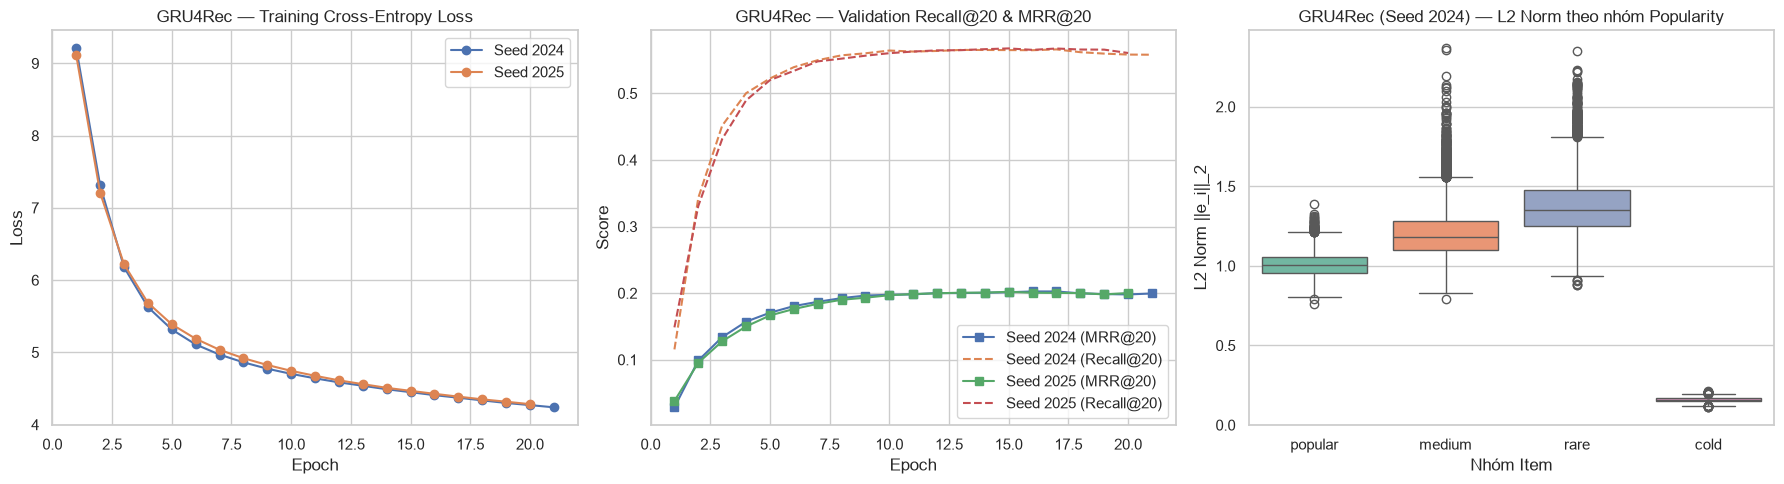

,seed,file,exists,size_kb
0,2024,config.yaml,True,3.4900
1,2024,checkpoint.pth,True,"9,760.1200"
2,2024,training.log,True,4.7200
3,2024,training_history.csv,True,2.6400
4,2024,test_metrics.json,True,5.0100
5,2024,top20.parquet,True,"6,369.0400"
6,2024,item_embeddings.npy,True,"9,395.8800"
7,2024,item_embedding_mapping.csv,True,"2,066.2000"
8,2025,config.yaml,True,3.4900
9,2025,checkpoint.pth,True,"9,760.1200"


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for seed, out in run_outputs.items():
    hist = out["history_df"]
    axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label=f"Seed {seed}")
    axes[1].plot(hist["epoch"], hist["validation_mrr@20"], marker="s", label=f"Seed {seed} (MRR@20)")
    axes[1].plot(hist["epoch"], hist["validation_recall@20"], linestyle="--", label=f"Seed {seed} (Recall@20)")

axes[0].set_title("GRU4Rec — Training Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("GRU4Rec — Validation Recall@20 & MRR@20")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()

first_seed = CONFIG["seeds"][0]
il_df = run_outputs[first_seed]["item_level_df"]
sns.boxplot(
    data=il_df,
    x="popularity_group",
    y="embedding_norm",
    order=["popular", "medium", "rare", "cold"],
    palette="Set2",
    ax=axes[2],
)
axes[2].set_title(f"GRU4Rec (Seed {first_seed}) — L2 Norm theo nhóm Popularity")
axes[2].set_xlabel("Nhóm Item")
axes[2].set_ylabel("L2 Norm ||e_i||_2")

plt.tight_layout()
plt.show()

# Kiểm tra đủ 8 file đầu ra trong mỗi thư mục seed
REQUIRED_FILES = [
    "config.yaml",
    "checkpoint.pth",
    "training.log",
    "training_history.csv",
    "test_metrics.json",
    "top20.parquet",
    "item_embeddings.npy",
    "item_embedding_mapping.csv",
]

manifest_rows = []
for seed, out in run_outputs.items():
    rdir = out["run_dir"]
    for fname in REQUIRED_FILES:
        fpath = rdir / fname
        manifest_rows.append({
            "seed": seed,
            "file": fname,
            "exists": fpath.is_file(),
            "size_kb": round(fpath.stat().st_size / 1024.0, 2) if fpath.is_file() else 0.0,
        })

manifest_df = pd.DataFrame(manifest_rows)
assert manifest_df["exists"].all(), "Thiếu file bàn giao trong runs/gru4rec!"
display(manifest_df)